**Experiment Overview**

We perform turn-level intent classification, where each labeled user turn is one instance. For each turn, the input consists of the previous turns in the same conversation plus the current turn. Train/test splitting is done at the conversation level so that conversations remain intact and no dialogue is shared across train and test.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score

warnings.filterwarnings("ignore")

In [3]:
from pathlib import Path

data_candidates = [
    Path("DATA/ORIGINAL DATA/conversation_en.json"),
    Path("../DATA/ORIGINAL DATA/conversation_en.json"),
]
DATA_PATH = next((path for path in data_candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not locate DATA/ORIGINAL DATA/conversation_en.json")

with DATA_PATH.open("r", encoding="utf-8") as f:
    raw = json.load(f)

rows = []
for conv in raw:
    conv_id = conv.get("conv_id")
    turns = conv.get("conversation", [])

    for i, t in enumerate(turns):
        rows.append({
            "conversation_id": str(conv_id),
            "turn_index": int(i),                      # order of turns within each conversation
            "role": str(t.get("role", "")).lower(),   # normalize role
            "text": t.get("content"),
            "intent": t.get("intent")
        })

df_turns = pd.DataFrame(rows)

display(df_turns.head())

#print("Total turns:", len(df_turns))
print("Total conversations:", df_turns["conversation_id"].nunique())
print("Average turns per conversation:",
      round(len(df_turns) / df_turns["conversation_id"].nunique(), 2))

# keep only user turns
df_user = df_turns[df_turns["role"] == "user"].copy()

# keep only labeled user turns
df_labeled = df_user[df_user["intent"].notna()].copy()

# this is the dataframe used later for training instances
df = df_labeled.copy()

print("\nLabeled user turns:", len(df))

dist = df["intent"].value_counts()
pct = (dist / dist.sum() * 100).round(2)

print("\nIntent distribution:")
print(pd.DataFrame({"count": dist, "percent": pct}))

,conversation_id,turn_index,role,text,intent
0,19762,0,user,"Hello, i would like to purchase a new fridge",Reveal
1,19762,1,system,What size fridge are you looking for?,None
2,19762,2,system,Also in what price range are you looking?,None
3,19762,3,user,"I am looking for a new table sized fridge, sin...",Interpret
4,19762,4,user,Can you check for price ranges below 200 euros?,Interpret


Total conversations: 826
Average turns per conversation: 6.82

Labeled user turns: 3196

Intent distribution:
           count  percent
Interpret   1813    56.73
Reveal      1031    32.26
Chitchat     268     8.39
Revise        67     2.10
Inquire       17     0.53


In [4]:
turns_by_conv = {
    cid: g.sort_values("turn_index")
    for cid, g in df_turns.groupby("conversation_id")
}

X, y, groups = [], [], []

for _, row in df.iterrows():
    cid = row["conversation_id"]
    ti = row["turn_index"]

    conv_turns = turns_by_conv[cid]

    # previous turns only
    prev = conv_turns[conv_turns["turn_index"] < ti]

    history = []
    for _, p in prev.iterrows():
        role = (p["role"] or "unknown").upper()
        text = (p["text"] or "").strip()
        if text:
            history.append(f"{role}: {text}")

    current_turn = (row["text"] or "").strip()

    if history:
        full_text = " \n ".join(history) + " \n " + f"USER: {current_turn}"
    else:
        full_text = f"USER: {current_turn}"

    X.append(full_text)
    y.append(row["intent"])
    groups.append(cid)

X = np.array(X)
y = np.array(y)
groups = np.array(groups)

In [5]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Train turns:", len(X_train), "Test turns:", len(X_test))
print("\nTrain intent counts:")
print(pd.Series(y_train).value_counts())

print("\nTest intent counts:")
print(pd.Series(y_test).value_counts())

print("\nUnique train conversations:", len(set(groups[train_idx])))
print("Unique test conversations:", len(set(groups[test_idx])))

Train turns: 2544 Test turns: 652

Train intent counts:
Interpret    1435
Reveal        838
Chitchat      204
Revise         55
Inquire        12
dtype: int64

Test intent counts:
Interpret    378
Reveal       193
Chitchat      64
Revise        12
Inquire        5
dtype: int64

Unique train conversations: 660
Unique test conversations: 166


In [6]:
train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

print("Train turns:", len(train_df))
print("Test turns:", len(test_df))

print("Unique train conversations:", train_df["conversation_id"].nunique())
print("Unique test conversations:", test_df["conversation_id"].nunique())

Train turns: 2544
Test turns: 652
Unique train conversations: 660
Unique test conversations: 166


In [7]:
train_df.to_csv("train_turns_new.csv", index=False)
test_df.to_csv("test_turns_new.csv", index=False)

In [8]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95
    )),
    ("clf", LogisticRegression(
        max_iter=2000,
        class_weight="balanced" 
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

    Chitchat      0.700     0.656     0.677        64
     Inquire      0.000     0.000     0.000         5
   Interpret      0.872     0.862     0.867       378
      Reveal      0.734     0.788     0.760       193
      Revise      0.000     0.000     0.000        12

    accuracy                          0.798       652
   macro avg      0.461     0.461     0.461       652
weighted avg      0.791     0.798     0.794       652



In [9]:
labels = sorted(list(set(y_test) | set(y_pred)))
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f"true:{l}" for l in labels], columns=[f"pred:{l}" for l in labels])
cm_df

,pred:Chitchat,pred:Inquire,pred:Interpret,pred:Reveal,pred:Revise
true:Chitchat,42,2,12,8,0
true:Inquire,1,0,0,4,0
true:Interpret,10,0,326,39,3
true:Reveal,7,2,28,152,4
true:Revise,0,0,8,4,0


In [10]:

models = {
    "Naive Bayes (Complement)": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=1, max_df=0.95)),
        ("clf", ComplementNB())  # better than MultinomialNB for imbalanced text
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=1, max_df=0.95)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0))
    ]),
    "Random Forest": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=1, max_df=0.95)),
        ("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42))
    ]),
    "SVM": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=1, max_df=0.95)),
        ("clf", LinearSVC(class_weight="balanced", max_iter=2000, C=1.0))
    ]),
}

print("=" * 60)
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    print(f"\n### {name} ###")
    print(classification_report(y_test, y_pred, digits=3))
    print("=" * 60)


### Naive Bayes (Complement) ###
              precision    recall  f1-score   support

    Chitchat      0.897     0.547     0.680        64
     Inquire      0.000     0.000     0.000         5
   Interpret      0.747     0.955     0.839       378
      Reveal      0.777     0.523     0.625       193
      Revise      0.000     0.000     0.000        12

    accuracy                          0.762       652
   macro avg      0.484     0.405     0.429       652
weighted avg      0.751     0.762     0.738       652


### Logistic Regression ###
              precision    recall  f1-score   support

    Chitchat      0.745     0.641     0.689        64
     Inquire      0.000     0.000     0.000         5
   Interpret      0.868     0.868     0.868       378
      Reveal      0.733     0.798     0.764       193
      Revise      0.000     0.000     0.000        12

    accuracy                          0.802       652
   macro avg      0.469     0.461     0.464       652
weighted avg  

In [11]:
errors = []

for text, true, pred in zip(X_test, y_test, y_pred):
    if true != pred:
        errors.append((text, true, pred))

error_df = pd.DataFrame(errors, columns=["text", "true_label", "predicted_label"])

error_df.head(15)

,text,true_label,predicted_label
0,USER: I'd like to buy a sport coat. \n SYSTEM:...,Interpret,Reveal
1,"USER: I'm going to go mountain climbing, but I...",Reveal,Interpret
2,USER: I'd like to buy some stationery. \n SYST...,Interpret,Reveal
3,USER: Hi! I like starcraft2 very much! Please ...,Reveal,Interpret
4,"USER: I'm bored now, is there any topic?",Chitchat,Reveal
5,"USER: I'm bored now, is there any topic? \n SY...",Reveal,Interpret
6,"USER: I'm bored now, is there any topic? \n SY...",Chitchat,Interpret
7,USER: hello. \n SYSTEM: Do you need any help f...,Reveal,Interpret
8,USER: hello \n SYSTEM: Hello. Is there anythin...,Revise,Interpret
9,USER: I need to buy a computer screen. \n USER...,Revise,Interpret


In [12]:
confused = error_df.groupby(["true_label","predicted_label"]).size().reset_index(name="count")
confused.sort_values("count", ascending=False).head(10)

,true_label,predicted_label,count
9,Reveal,Interpret,31
6,Interpret,Reveal,27
1,Chitchat,Interpret,16
2,Chitchat,Reveal,10
12,Revise,Interpret,9
4,Inquire,Reveal,4
7,Reveal,Chitchat,4
5,Interpret,Chitchat,2
8,Reveal,Inquire,2
13,Revise,Reveal,2


We implemented a classical ML baseline for PSCon T1 intent classification. Each labeled user turn is treated as one instance, and the input for each turn consists of the previous turns from the same conversation plus the current turn. Train/test splitting is performed at the conversation level using GroupShuffleSplit, so all turns from a conversation remain intact in either train or test. This avoids leakage while preserving dialogue history for context-aware intent prediction.

In [13]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# keep label order fixed
labels = ["Chitchat", "Inquire", "Interpret", "Reveal", "Revise"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=[f"true_{label}" for label in labels],
    columns=[f"pred_{label}" for label in labels]
)

print("=== CONFUSION MATRIX ===")
print(cm_df)

=== CONFUSION MATRIX ===
                pred_Chitchat  pred_Inquire  pred_Interpret  pred_Reveal  \
true_Chitchat              37             1              16           10   
true_Inquire                0             0               1            4   
true_Interpret              2             0             349           27   
true_Reveal                 4             2              31          155   
true_Revise                 1             0               9            2   

                pred_Revise  
true_Chitchat             0  
true_Inquire              0  
true_Interpret            0  
true_Reveal               1  
true_Revise               0  


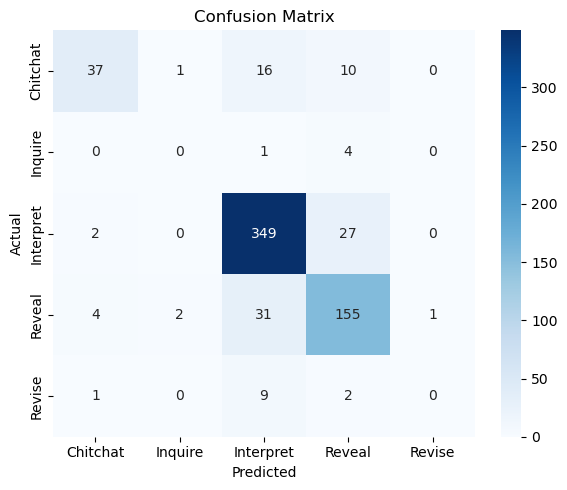

In [14]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()